<h1>Notebook para Cyanobacterias</h1>

In [11]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import hamming
import gudhi as gd
import seaborn as sns
from statistics import mode
import multiprocessing
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
import gudhi as gd
# from scipy.spatial.distance import hamming
import plotly.graph_objs as go
import networkx as nx
import plotly.graph_objects as go
import plotly.io as pio
from networkx.utils import not_implemented_for, pairwise
from concurrent.futures import ThreadPoolExecutor, as_completed
import plotly
import plotly.express as px
from module_functions import *

<h2>Se extrae la información </h2>

In [2]:
info=pd.read_csv('data/pscpCyanos.blast',sep='\t',header=None)
names=pd.read_csv('data/Cyanobacteria.ids',sep='\t',dtype='object',header=None)

<h2>Se crean los data frames</h2>

In [3]:
df_by_pathway,df_by_pathway_drop_duplicate,representative_genomes=get_df_by_pathway(info)

In [4]:
print('n genomas:',len(df_by_pathway['3PGA_AMINOACIDS'].index))
cont=0
cont2=0
for i,j in df_by_pathway.items():
    cont2+=len(j.columns)
    cont+=1
    print(i)
print('n rutas',cont)
print('n genes',cont2)

n genomas: 416
TCA
R5P_AMINOACIDS
OXALACETATE_AMINOACIDS
3PGA_AMINOACIDS
Glycolysis
calcium-dependent-antibiotic
E4P_AMINO_ACIDS
polyketide
PYR_THR_AA
ALPHAKETOGLUTARATE_AMINOACIDS
n rutas 10
n genes 44


In [171]:
dict_names=dict(names.set_index(2)[1])

In [165]:
L=set(['Prochlorococcus sp MIT 0602 MIT 0602 JNAV01','Synechococcus sp RS9917 RS9917; RCC556 AANP01',
       'Prochlorococcus marinus str GP2 GP2 JNAH01','Synechococcus sp WH 7805 WH 7805 AAOK01','Prochlorococcus sp MIT 0603 MIT 0603 JNAW01'])

In [172]:
K=[]
for i in L:
    K.append(dict_names[i])

In [177]:
for path in representative_genomes.keys():
    for key in representative_genomes[path].keys():
        if set(K).issubset(set(representative_genomes[path][key])):
            print(len(representative_genomes[path][key]),path)

168 TCA
67 R5P_AMINOACIDS
75 OXALACETATE_AMINOACIDS
197 3PGA_AMINOACIDS
180 Glycolysis
319 calcium-dependent-antibiotic
149 E4P_AMINO_ACIDS
367 polyketide
102 PYR_THR_AA
60 ALPHAKETOGLUTARATE_AMINOACIDS


In [157]:
dict_names

{'6666666.212472': 'Acaryochloris marina MBIC11017 CP000828.1',
 '6666666.212119': 'Acaryochloris sp CCMEE 5410 CCMEE 5410 AFEJ01',
 '6666666.212289': 'Aliterella atlantica CENA595 CENA595 JYON01',
 '6666666.212383': 'Anabaena cylindrica PCC 7122 CP003659.1',
 '6666666.212224': 'Anabaena sp 39858 LJOR01',
 '6666666.212218': 'Anabaena sp 39864 LJOQ01',
 '6666666.212364': 'Anabaena sp 39865 LJOP01',
 '6666666.212200': 'Anabaena sp 4_3 4_3 LUHJ01',
 '6666666.212249': 'Anabaena sp CA = ATCC 33047 ATCC 33047 LUHI01',
 '6666666.212103': 'Anabaena sp CRKS33 LJOT01',
 '6666666.212356': 'Anabaena sp MDT14b LJOV01',
 '6666666.212296': 'Anabaena sp PCC 7108 PCC 7108 AJWF01',
 '6666666.212348': 'Anabaena sp WA113 LJOS01',
 '6666666.212133': 'Anabaena sp WA93 LJOU01',
 '6666666.212462': 'Anabaena sp. 90 CP003284.1',
 '6666666.212387': 'Anabaena sp. wa102 CP011456.1',
 '6666666.212388': 'Anabaena variabilis ATCC 29413 CP000117.1',
 '6666666.212221': 'Aphanizomenon flos_aquae 2012/KM1/D3 2012/KM1/D3 

<h2> Se crea el complejo simplicial</h2>

In [5]:
complex_pathways=get_complex_by_pathways(df_by_pathway_drop_duplicate)

In [10]:
complex_pathways['R5P_AMINOACIDS']
for i in complex_pathways.keys():
    contador=0
    for j in complex_pathways[i][0]:
        if j[0]==1:
            contador+=1
    print(i,contador)

TCA 7
R5P_AMINOACIDS 67
OXALACETATE_AMINOACIDS 39
3PGA_AMINOACIDS 7
Glycolysis 11
calcium-dependent-antibiotic 0
E4P_AMINO_ACIDS 80
polyketide 0
PYR_THR_AA 44
ALPHAKETOGLUTARATE_AMINOACIDS 66


In [6]:
#plot_all_bar_code_pathways(complex_pathways)

<h2>Se buscan los uno hoyos</h2>

In [7]:
holes_no_names,holes_with_names,holes_per_filt_lvl=get_holes_by_pathways(complex_pathways,df_by_pathway_drop_duplicate)

se buscan ciclos en el tiempo 2.0 para TCA
se buscan ciclos en el tiempo 2.0 para R5P_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para OXALACETATE_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para 3PGA_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para Glycolysis
Se encontró el ciclo [5, 8, 4, 1] en el tiempo 1.0 para TCA
Se encontró el ciclo [8, 0, 7, 4] en el tiempo 1.0 para TCA
Se encontró el ciclo [9, 3, 4, 1] en el tiempo 1.0 para TCA
Se encontró el ciclo [7, 0, 6, 2] en el tiempo 1.0 para TCA
Se encontró el ciclo [13, 15, 9, 1] en el tiempo 1.0 para TCA
Se encontró el ciclo [5, 6, 2, 1] en el tiempo 1.0 para TCA
Se encontró el ciclo [4, 7, 2, 1] en el tiempo 1.0 para TCA
Terminó la ruta  TCA
se buscan ciclos en el tiempo 2.0 para E4P_AMINO_ACIDS
Se encontró el ciclo [4, 21, 2, 1] en el tiempo 1.0 para Glycolysis
Se encontró el ciclo [8, 12, 5, 1] en el tiempo 1.0 para Glycolysis
Se encontró el ciclo [12, 6, 10, 5] en el tiempo 1.0 para Glycolysis
Se encontró el ciclo [19, 10, 5, 

In [71]:
resum=get_resum_df(df_by_pathway,representative_genomes,names,complex_pathways,holes_with_names)
resum

/opt/conda/envs/TDA/lib/python3.7/site-packages/pandas/core/internals/blocks.py:937: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr_value = np.asarray(value)


,num_columnas,num_hoyos,ciclos,ciclos por genero,duración hoyos
TCA,3,7,"[[[Richelia intracellularis HM01 HM01 CAIS01, ...","[[[Richelia, Prochlorothrix], Scytonema, [Arth...",[1.0]
R5P_AMINOACIDS,5,67,"[[[Prochlorococcus sp scB245a_519E23 JFNL01, P...","[[[Prochlorococcus, Prochlorococcus, Prochloro...",[1.0]
OXALACETATE_AMINOACIDS,5,39,[[[Prochlorothrix hollandica PCC 9006 PCC 9006...,"[[[Prochlorothrix, Thermosynechococcus], [Pseu...",[1.0]
3PGA_AMINOACIDS,2,7,"[[[Prochlorococcus sp W3 ALPC01, Prochlorococc...","[[[Prochlorococcus, Prochlorococcus, Prochloro...",[1.0]
Glycolysis,3,11,"[[[Prochlorococcus sp scB243_497J18 JFMJ01, Pr...","[[[Prochlorococcus, Prochlorococcus, Prochloro...",[1.0]
calcium-dependent-antibiotic,1,0,[],[],[]
E4P_AMINO_ACIDS,7,80,"[[[Planktothricoides sp SR001 SR001 LIUQ01, Mi...","[[[Planktothricoides, Microcystis], Candidatus...",[1.0]
polyketide,1,0,[],[],[]
PYR_THR_AA,5,44,"[[[Prochlorococcus sp scB245a_520D2 JFNR01, Pr...","[[[Prochlorococcus, Prochlorococcus, Prochloro...",[1.0]
ALPHAKETOGLUTARATE_AMINOACIDS,12,65,[[Scytonema hofmannii PCC 7110 PCC 7110 ANNX02...,"[[Scytonema, Aphanocapsa, Microcystis, [Cylind...","[1.0, 2.0]"


In [72]:
generos=set()
for i in traduced_df(df_by_pathway['R5P_AMINOACIDS'],names).index:
    generos.add(i.split(' ')[0])
df_count_genomes=pd.DataFrame(index=generos)
df_count_genomes['conteo']=0
for path in resum.index:
    ciclos_path=resum.loc[path,'ciclos por genero']
    for cic in ciclos_path:
        for vert in cic:
            if type(vert)==str:
                df_count_genomes.loc[vert,'conteo']=df_count_genomes.loc[vert,'conteo']+1
            else:
                for i in vert:
                    df_count_genomes.loc[i,'conteo']=df_count_genomes.loc[i,'conteo']+1
(df_count_genomes.sort_values(by='conteo',ascending=False)/df_count_genomes.sum())*100

,conteo
Prochlorococcus,41.445771
Synechococcus,16.176328
Microcystis,3.626566
Arthrospira,2.184678
Synechocystis,2.179823
...,...
Limnoraphis,0.063113
Aphanocapsa,0.058258
Mastigocladus,0.038839
Mastigocoleus,0.024274


<Figure size 1000x600 with 0 Axes>

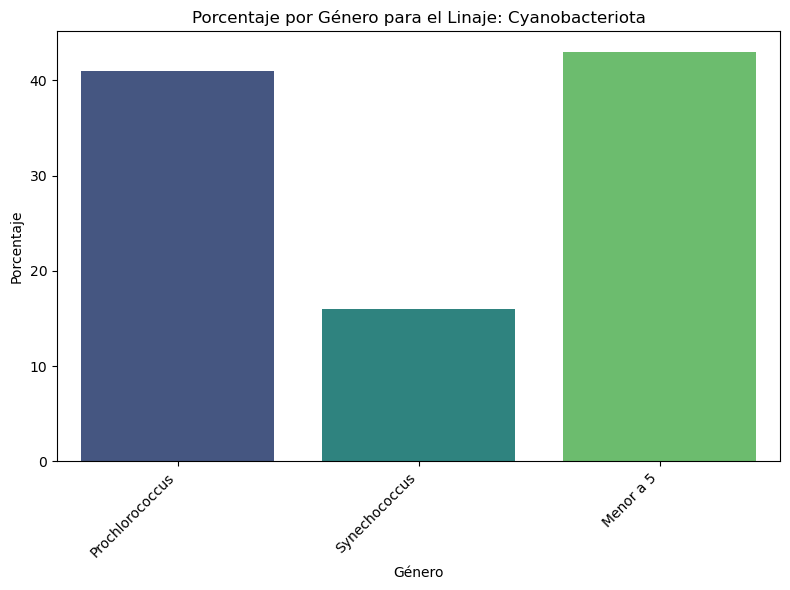

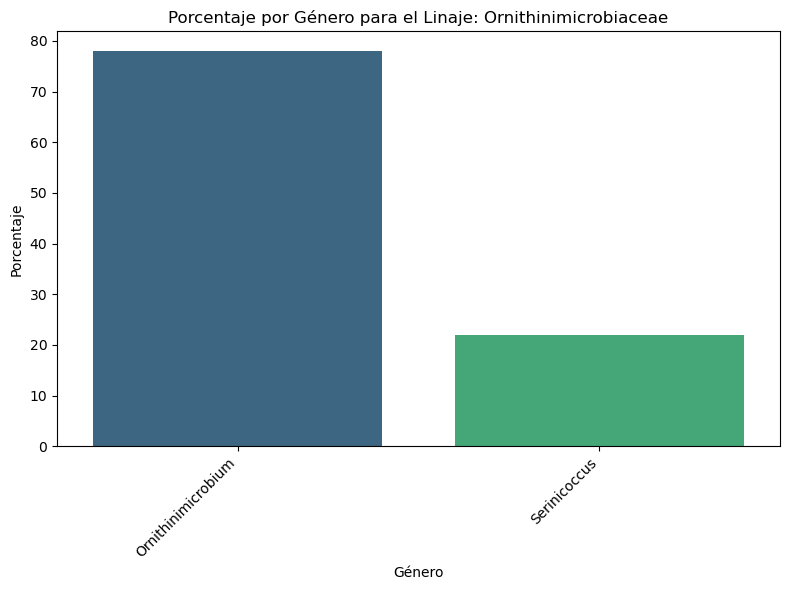

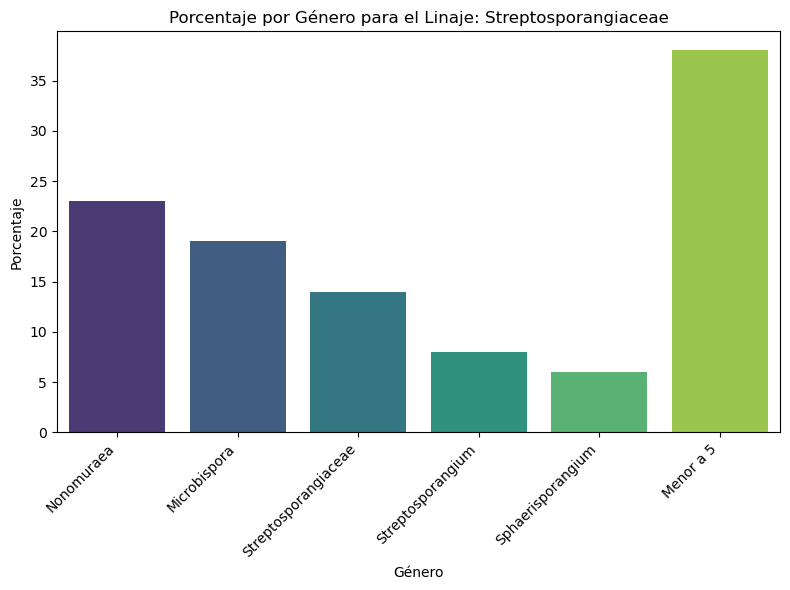

In [98]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Crear el DataFrame
para_graficar = pd.DataFrame()

# Asignar datos al DataFrame
para_graficar.loc[1, 'Género'] = 'Prochlorococcus'
para_graficar.loc[1, 'Porcentaje'] = 41
para_graficar.loc[2, 'Género'] = 'Synechococcus'
para_graficar.loc[2, 'Porcentaje'] = 16
para_graficar.loc[3, 'Género'] = 'Menor a 5'
para_graficar.loc[3, 'Porcentaje'] = 100 - (41 + 16)
para_graficar.loc[1:3, 'Linaje'] = 'Cyanobacteriota'

para_graficar.loc[4, 'Género'] = 'Ornithinimicrobium'
para_graficar.loc[4, 'Porcentaje'] = 78
para_graficar.loc[5, 'Género'] = 'Serinicoccus'
para_graficar.loc[5, 'Porcentaje'] = 100 - 78
para_graficar.loc[4:5, 'Linaje'] = 'Ornithinimicrobiaceae'

para_graficar.loc[6, 'Género'] = 'Nonomuraea'
para_graficar.loc[6, 'Porcentaje'] = 23
para_graficar.loc[7, 'Género'] = 'Microbispora'
para_graficar.loc[7, 'Porcentaje'] = 19
para_graficar.loc[8, 'Género'] = 'Streptosporangiaceae'
para_graficar.loc[8, 'Porcentaje'] = 14
para_graficar.loc[9, 'Género'] = 'Streptosporangium'
para_graficar.loc[9, 'Porcentaje'] = 8
para_graficar.loc[10, 'Género'] = 'Sphaerisporangium'
para_graficar.loc[10, 'Porcentaje'] = 6
para_graficar.loc[11, 'Género'] = 'Menor a 5'
para_graficar.loc[11, 'Porcentaje'] = 100 - (23 + 19 + 14 + 6)
para_graficar.loc[6:11, 'Linaje'] = 'Streptosporangiaceae'

# Establecer tamaño para las gráficas
plt.figure(figsize=(10, 6))

# Agrupar por Linaje
linajes = para_graficar['Linaje'].unique()

# Crear una gráfica por cada linaje
for linaje in linajes:
    # Filtrar los datos por linaje
    subset = para_graficar[para_graficar['Linaje'] == linaje]
    
    # Crear una figura para cada linaje
    plt.figure(figsize=(8, 6))
    
    # Graficar barras
    sns.barplot(data=subset, x='Género', y='Porcentaje', palette='viridis')
    
    # Título y etiquetas
    plt.title(f'Porcentaje por Género para el Linaje: {linaje}')
    plt.xlabel('Género')
    plt.ylabel('Porcentaje')
    plt.xticks(rotation=45, ha='right')
    
    # Mostrar la gráfica
    plt.tight_layout()
    plt.show()


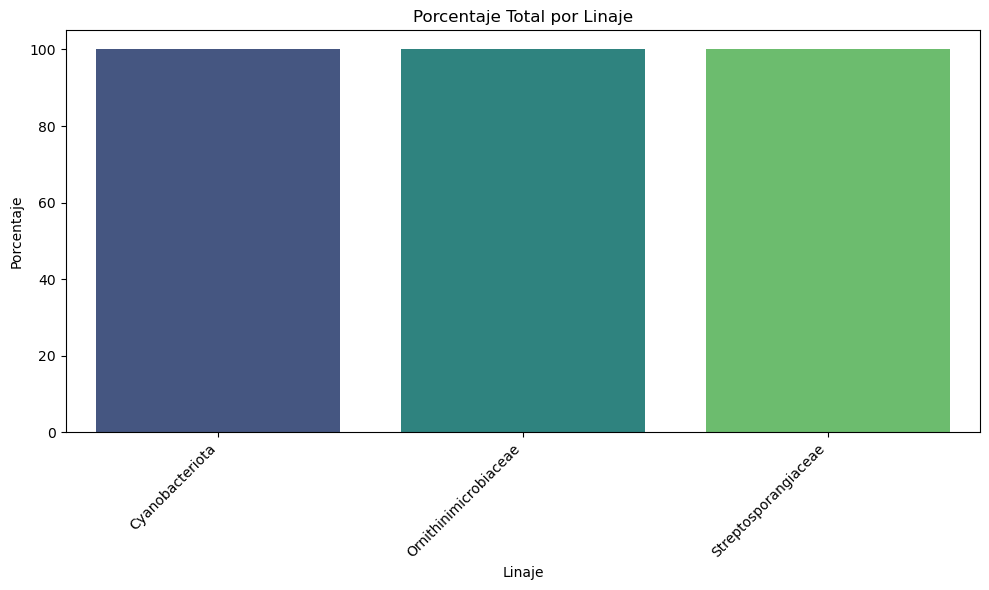

In [101]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Crear el DataFrame
para_graficar = pd.DataFrame()

# Asignar datos al DataFrame
para_graficar.loc[1, 'Género'] = 'Prochlorococcus'
para_graficar.loc[1, 'Porcentaje'] = 41
para_graficar.loc[2, 'Género'] = 'Synechococcus'
para_graficar.loc[2, 'Porcentaje'] = 16
para_graficar.loc[3, 'Género'] = 'Menor a 5'
para_graficar.loc[3, 'Porcentaje'] = 100 - (41 + 16)
para_graficar.loc[1:3, 'Linaje'] = 'Cyanobacteriota'

para_graficar.loc[4, 'Género'] = 'Ornithinimicrobium'
para_graficar.loc[4, 'Porcentaje'] = 78
para_graficar.loc[5, 'Género'] = 'Serinicoccus'
para_graficar.loc[5, 'Porcentaje'] = 100 - 78
para_graficar.loc[4:5, 'Linaje'] = 'Ornithinimicrobiaceae'

para_graficar.loc[6, 'Género'] = 'Nonomuraea'
para_graficar.loc[6, 'Porcentaje'] = 23
para_graficar.loc[7, 'Género'] = 'Microbispora'
para_graficar.loc[7, 'Porcentaje'] = 19
para_graficar.loc[8, 'Género'] = 'Streptosporangiaceae'
para_graficar.loc[8, 'Porcentaje'] = 14
para_graficar.loc[9, 'Género'] = 'Streptosporangium'
para_graficar.loc[9, 'Porcentaje'] = 8
para_graficar.loc[10, 'Género'] = 'Sphaerisporangium'
para_graficar.loc[10, 'Porcentaje'] = 6
para_graficar.loc[11, 'Género'] = 'Menor a 5'
para_graficar.loc[11, 'Porcentaje'] = 100 - (23 + 19 + 14 + 6+8)
para_graficar.loc[6:11, 'Linaje'] = 'Streptosporangiaceae'

# Agrupar por Linaje y sumar los porcentajes
df_linajes = para_graficar.groupby('Linaje')['Porcentaje'].sum().reset_index()

# Crear la gráfica de barras
plt.figure(figsize=(10, 6))
sns.barplot(data=df_linajes, x='Linaje', y='Porcentaje', palette='viridis')

# Título y etiquetas
plt.title('Porcentaje Total por Linaje')
plt.xlabel('Linaje')
plt.ylabel('Porcentaje')
plt.xticks(rotation=45, ha='right')

# Mostrar la gráfica
plt.tight_layout()
plt.show()


In [110]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.switch_backend('Agg') 
# Crear el DataFrame
para_graficar = pd.DataFrame()

# Asignar datos al DataFrame
para_graficar.loc[1, 'Género'] = 'Prochlorococcus'
para_graficar.loc[1, 'Porcentaje'] = 41
para_graficar.loc[2, 'Género'] = 'Synechococcus'
para_graficar.loc[2, 'Porcentaje'] = 16
para_graficar.loc[3, 'Género'] = 'Menor a 5%'
para_graficar.loc[3, 'Porcentaje'] = 100 - (41 + 16)
para_graficar.loc[1:3, 'Linaje'] = 'Cyanobacteriota'

para_graficar.loc[4, 'Género'] = 'Ornithinimicrobium'
para_graficar.loc[4, 'Porcentaje'] = 78
para_graficar.loc[5, 'Género'] = 'Serinicoccus'
para_graficar.loc[5, 'Porcentaje'] = 100 - 78
para_graficar.loc[4:5, 'Linaje'] = 'Ornithinimicrobiaceae'

para_graficar.loc[6, 'Género'] = 'Nonomuraea'
para_graficar.loc[6, 'Porcentaje'] = 23
para_graficar.loc[7, 'Género'] = 'Microbispora'
para_graficar.loc[7, 'Porcentaje'] = 19
para_graficar.loc[8, 'Género'] = 'Streptosporangiaceae'
para_graficar.loc[8, 'Porcentaje'] = 14
para_graficar.loc[9, 'Género'] = 'Streptosporangium'
para_graficar.loc[9, 'Porcentaje'] = 8
para_graficar.loc[10, 'Género'] = 'Sphaerisporangium'
para_graficar.loc[10, 'Porcentaje'] = 6
para_graficar.loc[11, 'Género'] = 'Menor a 5%'
para_graficar.loc[11, 'Porcentaje'] = 100 - (23 + 19 + 14 + 6+8)
para_graficar.loc[6:11, 'Linaje'] = 'Streptosporangiaceae'

# Crear la gráfica apilada por linaje
# Primero, agrupamos los géneros por linaje
df_linajes = para_graficar.pivot_table(values='Porcentaje', index='Linaje', columns='Género', aggfunc='sum', fill_value=0)

# Crear la gráfica apilada
ax = df_linajes.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set3')

# Título y etiquetas

plt.xlabel('Linaje')
plt.ylabel('Porcentaje')
plt.xticks(rotation=0)

# Mostrar la leyenda
plt.legend(title='Género', bbox_to_anchor=(1.05, 1), loc='upper left')

# Ajustar la visualización
plt.tight_layout()
plt.show()
plt.savefig('representacion_generos_linajes.svg',format='svg')


In [84]:
generos=set()
for i in traduced_df(df_by_pathway['R5P_AMINOACIDS'],names).index:
    generos.add(i.split(' ')[0])
df_count_genomes=pd.DataFrame(index=traduced_df(df_by_pathway['R5P_AMINOACIDS'],names).index)
df_count_genomes['conteo']=0
for path in resum.index:
    ciclos_path=resum.loc[path,'ciclos']
    for cic in ciclos_path:
        for vert in cic:
            if type(vert)==str:
                df_count_genomes.loc[vert,'conteo']=df_count_genomes.loc[vert,'conteo']+1
            else:
                for i in vert:
                    df_count_genomes.loc[i,'conteo']=df_count_genomes.loc[i,'conteo']+1
df_count_genomes.sort_values(by='conteo',ascending=False).head(13)

,conteo
R5P_AMINOACIDS,
Prochlorococcus sp MIT 0602 MIT 0602 JNAV01,97
Synechococcus sp RS9917 RS9917; RCC556 AANP01,97
Prochlorococcus marinus str GP2 GP2 JNAH01,97
Synechococcus sp WH 7805 WH 7805 AAOK01,97
Prochlorococcus sp MIT 0603 MIT 0603 JNAW01,97
Synechococcus sp. CC9902 CP000097.1,97
Synechococcus sp MIT S9509 MIT S9509 LVHV01,97
Prochlorococcus marinus str. NATL2A CP000095.2,97
Synechococcus sp RS9916 RS9916 AAUA01,97


In [78]:
long=[]
for k in resum.index:
    for i in resum.loc[k,'ciclos']:
        long.append(len(i))
print(set(long))
long.count(4)

{8, 4, 5, 6}


304

<h2>Se ven los elementos que hacen el hoyo</h2>

In [67]:
df_pathway_make_hole=get_df_by_pathway_make_hole_droped_cols(df_by_pathway_drop_duplicate,holes_with_names)
df_count_genes_participation=pd.DataFrame()
for path in df_pathway_make_hole.keys():
    print('los genes que participan en los 1-hoyos para',path,'son:')
    genes=[]
    for df in df_pathway_make_hole[path]:
        genes.extend(list(df.columns))
    set_count_genes=set()
    for gen in genes:
        df_count_genes_participation.loc[gen,'conteo']=genes.count(gen)
        df_count_genes_participation.loc[gen,'ruta']=path
        set_count_genes.add(gen+':'+str(genes.count(gen)))
    print(str(set_count_genes))

los genes que participan en los 1-hoyos para TCA son:
{'fumarate_hydratase:4', 'fumarate_reductase_ironsulfur_subunit:4', 'Citrate_synthase:6'}
los genes que participan en los 1-hoyos para R5P_AMINOACIDS son:
{'imidazole_glycerol_phosphate_synthase_H:32', 'histidinol_dehydrogenase:28', 'ribosephosphate_pyrophosphokinase:24', 'phosphoribosyl_isomerase_A:31', 'imidazoleglycerol_phosphate_dehydratase:22'}
los genes que participan en los 1-hoyos para OXALACETATE_AMINOACIDS son:
{'dihydropicolinate_synthase:12', 'argininosuccinate_lyase:12', 'diaminopimelate_decarboxylase:16', 'Aspartate_transaminase:24', 'Threonine_synthase:19'}
los genes que participan en los 1-hoyos para 3PGA_AMINOACIDS son:
{'Cysteine_synthase:7', 'glycine_hydroxymethyltransferase:7'}
los genes que participan en los 1-hoyos para Glycolysis son:
{'phosphoglycerate_kinase:5', 'enolase:9', 'Pyruvate_kinase:8'}
los genes que participan en los 1-hoyos para calcium-dependent-antibiotic son:
set()
los genes que participan en l

In [70]:
total=df_count_genes_participation.sum()['conteo']
df_count_genes_participation.sort_values(by='conteo',ascending=False)
df_count_genes_participation.to_csv('2.csv')

In [31]:
df

20

In [26]:
['cddd','d','d'].count('d')

2

In [21]:
df_pathway_make_hole['R5P_AMINOACIDS'][0].columns

,imidazoleglycerol_phosphate_dehydratase,phosphoribosyl_isomerase_A
R5P_AMINOACIDS,,
6666666.212195,1.0,2.0
6666666.212362,0.0,2.0
6666666.212056,0.0,1.0
6666666.212054,1.0,1.0


In [11]:
traduced_df(df_pathway_make_hole['R5P_AMINOACIDS'][0],names)


,ribosephosphate_pyrophosphokinase,imidazoleglycerol_phosphate_dehydratase,phosphoribosyl_AMP_cyclohydrolase,histidinolphosphate_aminotransferase,phosphoribosyl_isomerase_A,histidinol_dehydrogenase,ATP_phosphoribosyltransferase,histidinol_phosphatase,imidazole_glycerol_phosphate_synthase_H
R5P_AMINOACIDS,,,,,,,,,
Serinicoccus sp. CNJ-927 CNJ-927,1.0,1.0,1.0,1.0,2,1.0,0.0,1.0,1.0
Ornithinimicrobium sp. na,0.0,1.0,0.0,1.0,2,1.0,0.0,1.0,2.0
Ornithinimicrobium humiphilum DSM 12362,1.0,1.0,0.0,2.0,2,1.0,1.0,1.0,2.0
Serinicoccus chungangensis CD08_5,1.0,1.0,1.0,2.0,2,1.0,1.0,1.0,2.0


<h2>Se buscan uno hoyos pero al separar por genero y ruta metabólica</h2>

In [7]:
df_by_genus_pathway,df_by_genus_pathway_drop_duplicate,representative_genomes_genus_pathway=get_df_by_genus_pathway(df_by_pathway,names)
complex_genus_pathways=get_complex_by_pathways(df_by_genus_pathway_drop_duplicate)

In [8]:
traduced_df(df_by_genus_pathway['Serinicoccus_ALPHAKETOGLUTARATE_AMINOACIDS'],names)

KeyError: 'Serinicoccus_ALPHAKETOGLUTARATE_AMINOACIDS'

In [14]:
holes_genus_no_names,holes_genus_with_names,holes_genus_per_filt_lvl=get_holes_by_pathways(complex_genus_pathways,df_by_genus_pathway_drop_duplicate)

se buscan ciclos en el tiempo 3.0 para Ornithinimicrobium_3PGA_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para Ornithinimicrobium_ALPHAKETOGLUTARATE_AMINOACIDS
Se encontró el ciclo [15, 10, 6, 1] en el tiempo 1.0 para Ornithinimicrobium_ALPHAKETOGLUTARATE_AMINOACIDS
Se encontró el ciclo [15, 4, 2, 1] en el tiempo 1.0 para Ornithinimicrobium_ALPHAKETOGLUTARATE_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para Ornithinimicrobium_PPP
Se encontró el ciclo [11, 3, 5, 2] en el tiempo 1.0 para Ornithinimicrobium_PPP
Se encontró el ciclo [10, 1, 5, 2] en el tiempo 2.0 para Ornithinimicrobium_3PGA_AMINOACIDS
se buscan ciclos en el tiempo 6.0 para Ornithinimicrobium_OXALACETATE_AMINOACIDS
Se encontró el ciclo [0, 14, 16, 2] en el tiempo 5.0 para Ornithinimicrobium_OXALACETATE_AMINOACIDS
Se encontró el ciclo [4, 7, 5, 2] en el tiempo 5.0 para Ornithinimicrobium_OXALACETATE_AMINOACIDS


In [16]:
resum_genus=get_resum_df(df_by_genus_pathway,representative_genomes_genus_pathway,names,complex_genus_pathways,holes_genus_with_names)
resum_genus

/opt/conda/envs/TDA/lib/python3.7/site-packages/pandas/core/internals/blocks.py:937: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr_value = np.asarray(value)


,num_columnas,num_hoyos,ciclos,ciclos por genero,duración hoyos
Serinicoccus_3PGA_AMINOACIDS,5,0,[],[],[]
Ornithinimicrobium_3PGA_AMINOACIDS,5,1,"[[Ornithinimicrobium sp. na, Ornithinimicrobiu...","[[Ornithinimicrobium, Ornithinimicrobium, [Orn...",[1.0]
Serinicoccus_E4P_AMINO_ACIDS,17,0,[],[],[]
Ornithinimicrobium_E4P_AMINO_ACIDS,17,0,[],[],[]
Serinicoccus_TCA,11,0,[],[],[]
Ornithinimicrobium_TCA,11,0,[],[],[]
Serinicoccus_ALPHAKETOGLUTARATE_AMINOACIDS,11,0,[],[],[]
Ornithinimicrobium_ALPHAKETOGLUTARATE_AMINOACIDS,11,2,"[[Ornithinimicrobium cerasi USBA17B2, Ornithin...","[[Ornithinimicrobium, Ornithinimicrobium, Orni...",[1.0]
Serinicoccus_R5P_AMINOACIDS,9,0,[],[],[]
Ornithinimicrobium_R5P_AMINOACIDS,9,0,[],[],[]


<h1>Para obtener la información de los 1-hoyos de la ruta R5P AMINOACIDS:</h1>

In [9]:
R5P_df_by_pathway={'R5P_AMINOACIDS':df_by_pathway['R5P_AMINOACIDS']}
R5P_df_by_pathway_drop_duplicate={'R5P_AMINOACIDS':df_by_pathway_drop_duplicate['R5P_AMINOACIDS']}
R5P_representative_genomes={'R5P_AMINOACIDS':representative_genomes['R5P_AMINOACIDS']}
R5P_complex_pathways={'R5P_AMINOACIDS':complex_pathways['R5P_AMINOACIDS']}

In [10]:
R5P_holes_no_names,R5P_holes_with_names,R5P_holes_per_filt_lvl=get_holes_by_pathways(R5P_complex_pathways,R5P_df_by_pathway_drop_duplicate)

se buscan ciclos en el tiempo 2.0 para R5P_AMINOACIDS
Se encontró el ciclo [63, 31, 55, 11] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [71, 52, 64, 57] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [27, 8, 24, 2] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [32, 60, 17, 4] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [41, 48, 24, 5] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [17, 53, 11, 4] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [11, 54, 5, 4] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [40, 10, 35, 21] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [28, 7, 23, 3] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [71, 57, 40, 10] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [75, 40, 29, 14] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [49, 69, 32, 4] en el tiempo 1.0 para R5P_AMINOACIDS
Se encontró el ciclo [59, 74, 44, 14] en el tiempo 1.0 p

In [15]:
get_resum_df(R5P_df_by_pathway,R5P_representative_genomes,names,R5P_complex_pathways,R5P_holes_with_names)

/opt/conda/envs/TDA/lib/python3.7/site-packages/pandas/core/internals/blocks.py:937: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr_value = np.asarray(value)


,num_columnas,num_hoyos,ciclos,ciclos por genero,duración hoyos
R5P_AMINOACIDS,5,67,"[[[Prochlorococcus sp scB245a_519E23 JFNL01, P...","[[[Prochlorococcus, Prochlorococcus, Prochloro...",[1.0]


<h3>Género por R5P</h3>

In [12]:
R5P_df_by_genus_pathway,R5P_df_by_genus_pathway_drop_duplicate,R5P_representative_genomes_genus_pathway=get_df_by_genus_pathway(R5P_df_by_pathway,names)
R5P_complex_genus_pathways=get_complex_by_pathways(R5P_df_by_genus_pathway_drop_duplicate)

In [13]:
R5P_holes_genus_no_names,R5P_holes_genus_with_names,R5P_holes_genus_per_filt_lvl=get_holes_by_pathways(R5P_complex_genus_pathways,R5P_df_by_genus_pathway_drop_duplicate)

se buscan ciclos en el tiempo 2.0 para Prochlorococcus_R5P_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para Synechococcus_R5P_AMINOACIDS
Se encontró el ciclo [3, 1, 2, 0] en el tiempo 1.0 para Synechococcus_R5P_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para Anabaena_R5P_AMINOACIDS
Se encontró el ciclo [5, 6, 3, 0] en el tiempo 1.0 para Anabaena_R5P_AMINOACIDS
se buscan ciclos en el tiempo 2.0 para Nostoc_R5P_AMINOACIDS
Se encontró el ciclo [4, 1, 3, 0] en el tiempo 1.0 para Nostoc_R5P_AMINOACIDS
se buscan ciclos en el tiempo 4.0 para Candidatus_R5P_AMINOACIDS
Se encontró el ciclo [2, 4, 1, 0] en el tiempo 3.0 para Candidatus_R5P_AMINOACIDS
Se encontró el ciclo [38, 26, 6, 2] en el tiempo 1.0 para Prochlorococcus_R5P_AMINOACIDS
Se encontró el ciclo [23, 33, 10, 2] en el tiempo 1.0 para Prochlorococcus_R5P_AMINOACIDS
Se encontró el ciclo [13, 6, 5, 0] en el tiempo 1.0 para Prochlorococcus_R5P_AMINOACIDS
Se encontró el ciclo [5, 20, 1, 0] en el tiempo 1.0 para Prochlorococcus_R5P_AMIN

In [15]:
get_resum_df(R5P_df_by_genus_pathway,R5P_representative_genomes_genus_pathway,names,R5P_complex_genus_pathways,R5P_holes_genus_with_names)

NameError: name 'R5P_df_by_genus_pathway' is not defined